In [13]:
# our libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# our library to help load dataset
from datasets import load_dataset

In [14]:
emotion_dataset = load_dataset("dair-ai/emotion")
train_text = emotion_dataset["train"]["text"]
train_label = emotion_dataset["train"]["label"]

test_text = emotion_dataset["test"]["text"]
test_label = emotion_dataset["test"]["label"]

In [15]:
label_names = emotion_dataset["train"].features["label"].names
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [16]:
df_train = pd.DataFrame(
    {
        "text"  : train_text,
        "label" : [label_names[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        "text"  : test_text,
        "label" : [label_names[i] for i in test_label]
    }
)
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [17]:
df_train.isnull().sum()

,0
text,0
label,0


<Axes: xlabel='label', ylabel='count'>

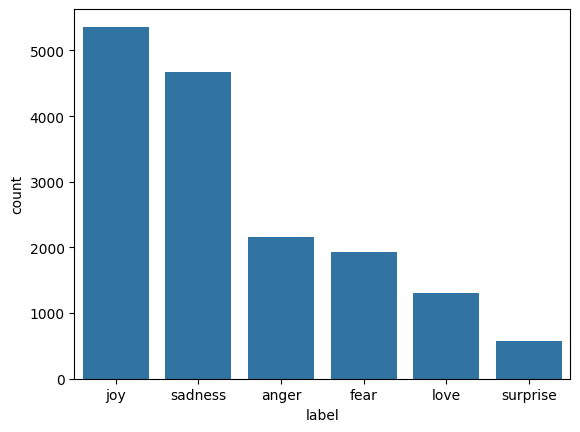

In [18]:
# EDA

sns.countplot(x="label", data=df_train, order= df_train["label"].value_counts().index)

In [19]:
# Data Preprocessing- Using NLP

# Tokenization breaks down raw text into smaller, meaningful units called tokens, which are then converted into numerical IDs for ML models.
    # Tokenizers split text based on predefined rules or statistical models and map each unique token to a specific integer ID from a vocabulary.
    # (if a unique val is not read during the training it's called out of vocabulary (oov) problem)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences # pad_sequences is a utility function in TensorFlow and Keras is the process of adding placeholder values,
                                                                  # typically zeros, to shorter text sequences so that all inputs in a batch have the same fixed length
max_words = 10000

tokenizer = Tokenizer(num_words=max_words,oov_token="<unk>")
tokenizer.fit_on_texts(df_train["text"]) # fit_on_texts is a method in class used to build a vocabulary dictionary from a list of text strings

train_sequence = tokenizer.texts_to_sequences(df_train["text"]) # tokenizer.texts_to_sequences() method in NLP transforms text strings into integer sequences
test_sequence = tokenizer.texts_to_sequences(df_test["text"])

padded_train_sequence = pad_sequences(train_sequence, maxlen= 50, padding= "post", truncating = "post")
padded_test_sequence = pad_sequences(test_sequence, maxlen= 50, padding= "post", truncating = "post")

train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequence.shape[1]}")

Vocabulary Size: 15213
Max Sentence Length: 50


In [20]:
from sklearn.utils import class_weight # Class weights are numerical values assigned to different classes in a classification task to handle imbalanced datasets,
                                       # where one class has significantly fewer samples than others.

class_weights = class_weight.compute_class_weight(
    class_weight="balanced", # "Figure out the weights automatically so rare classes get penalized more.
    classes = np.unique(train_labels),
    y = train_labels
)

class_weight_dict = dict(enumerate(class_weights))
class_weight_dict

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [21]:
from tensorflow.keras.callbacks import EarlyStopping # it's patience-based overfitting prevention — you stop at the best point instead of burning through all your epochs and memorizing noise.

early_stopping = EarlyStopping(
    monitor = "val_loss", # The number you're keeping an eye on every epoch. Usually val_loss (lower = better)
    patience = 3, # How long do you wait before giving up?
    restore_best_weights = True # Do you want the best version or the last one?
)

# Model 1 — Simple RNN

In [22]:
from tensorflow.keras.models import Sequential # A model that stacks layers one on top of another, like a pipeline.
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU
# SimpleRNN: The most basic RNN — reads words one by one, remembers a little of what came before.
# Embedding: Turns a word (or index) into a dense vector of numbers the model can actually learn from.
# Dense: A regular fully-connected layer — every input connects to every output.
# Dropout: Randomly "turns off" a fraction of neurons during training so the model doesn't memorize.
# LSTM: A smarter RNN with "gates" that decide what to remember/forget over long sequences.
# GRU: Like LSTM but simpler — fewer gates, faster, works almost as well.

rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim= 128, input_length= 50), # Turn each of my 50 words into a 128-number vector. max_words = size of your vocabulary.
    SimpleRNN(units=128, return_sequences=True), #  return_sequences: It returns all outputs — one vector per timestep
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5), # During training, randomly kill 50% of those 128 numbers so nothing overfits
    Dense(units= num_classes, activation= "softmax") # Take that summary and output a probability for each class.
])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
# optimizer='adam': The "learning rule" that updates weights each step.
# loss='sparse_categorical_crossentropy': My labels are integers (0, 1, 2), not one-hot vectors
# metrics=['accuracy']): Also show me % correct so I can track progress.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [24]:
rnn_model.fit(
    padded_train_sequence, # Your training data — the padded word sequences
    train_labels, # output
    validation_data=(padded_test_sequence, test_labels), # After each epoch, test on this data and report how I'm doing
    epochs = 20, # Train for at most 20 passes through the data. (Early stopping might cut it short.)
    batch_size=32, # Look at 32 examples at a time before updating weights
    class_weight=class_weight_dict, # The weights we computed earlier
    callbacks=[early_stopping] # Keep an eye out and stop me if I stop improving
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 33s 66ms/step - accuracy: 0.1558 - loss: 1.8114 - val_accuracy: 0.1385 - val_loss: 1.7995
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 60ms/step - accuracy: 0.1640 - loss: 1.7952 - val_accuracy: 0.1000 - val_loss: 1.8105
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 43s 63ms/step - accuracy: 0.1533 - loss: 1.7883 - val_accuracy: 0.1385 - val_loss: 1.7817
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.1385 - loss: 1.7995
RNN Loss: 1.7994903326034546
RNN Accuracy: 0.13850000500679016


# Model 2 — Standard LSTM

In [25]:
lstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim= 128, input_length= 50), # Turn each of my 50 words into a 128-number vector. max_words = size of your vocabulary.
    LSTM(units=128, return_sequences=True), #  return_sequences: It returns all outputs — one vector per timestep
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5), # During training, randomly kill 50% of those 128 numbers so nothing overfits
    Dense(units= num_classes, activation= "softmax") # Take that summary and output a probability for each class.
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence, # Your training data — the padded word sequences
    train_labels, # output
    validation_data=(padded_test_sequence, test_labels), # After each epoch, test on this data and report how I'm doing
    epochs = 20, # Train for at most 20 passes through the data. (Early stopping might cut it short.)
    batch_size=32, # Look at 32 examples at a time before updating weights
    class_weight=class_weight_dict, # The weights we computed earlier
    callbacks=[early_stopping] # Keep an eye out and stop me if I stop improving
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 74s 134ms/step - accuracy: 0.1417 - loss: 1.7949 - val_accuracy: 0.1380 - val_loss: 1.7772
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 163ms/step - accuracy: 0.1372 - loss: 1.7943 - val_accuracy: 0.1375 - val_loss: 1.7560
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 69s 137ms/step - accuracy: 0.1479 - loss: 1.7934 - val_accuracy: 0.2690 - val_loss: 1.7872
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 70s 140ms/step - accuracy: 0.1579 - loss: 1.7894 - val_accuracy: 0.2865 - val_loss: 1.7752
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 66s 131ms/step - accuracy: 0.1904 - loss: 1.7268 - val_accuracy: 0.2580 - val_loss: 1.5435
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 67s 134ms/step - accuracy: 0.2972 - loss: 1.4831 - val_accuracy: 0.3090 - val_loss: 1.5082
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 135ms/step - accuracy: 0.3884 - loss: 1.2411 - val_accuracy: 0.3725 - val_loss: 1.2573
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 67s 135ms/step - accuracy: 0.4599 - loss: 1.0421 - val

# Model 3 — Standard GRU

In [26]:
gru_model = Sequential([
    Embedding(input_dim=max_words, output_dim= 128, input_length= 50), # Turn each of my 50 words into a 128-number vector. max_words = size of your vocabulary.
    GRU(units=128, return_sequences=True), #  return_sequences: It returns all outputs — one vector per timestep
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5), # During training, randomly kill 50% of those 128 numbers so nothing overfits
    Dense(units= num_classes, activation= "softmax") # Take that summary and output a probability for each class.
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence, # Your training data — the padded word sequences
    train_labels, # output
    validation_data=(padded_test_sequence, test_labels), # After each epoch, test on this data and report how I'm doing
    epochs = 20, # Train for at most 20 passes through the data. (Early stopping might cut it short.)
    batch_size=32, # Look at 32 examples at a time before updating weights
    class_weight=class_weight_dict, # The weights we computed earlier
    callbacks=[early_stopping] # Keep an eye out and stop me if I stop improving
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {lstm_accuracy}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 62s 115ms/step - accuracy: 0.1559 - loss: 1.7969 - val_accuracy: 0.0330 - val_loss: 1.7946
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 114ms/step - accuracy: 0.1591 - loss: 1.7952 - val_accuracy: 0.1375 - val_loss: 1.7880
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 57s 113ms/step - accuracy: 0.1649 - loss: 1.7932 - val_accuracy: 0.3460 - val_loss: 1.7786
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.0330 - loss: 1.7946
GRU Loss: 1.7945642471313477
GRU Accuracy: 0.8740000128746033


# Model 4 — Advanced Stacked Bidirectional GRU
Enhance GRU with Bidirectional layers, 300D embeddings, and 0.5 dropout regularization.

In [32]:
from tensorflow.keras.layers import Bidirectional
# Bidirectional GRU reads our sentence twice — once left→right, once right→left — and stitches the two summaries together.

BIGRU_model = Sequential([
    Embedding(input_dim=max_words, output_dim= 300, input_length= 50), # Turn each of my 50 words into a 300-number vector. max_words = size of your vocabulary.
    Bidirectional(GRU(units=128, return_sequences=True)), #  return_sequences: It returns all outputs — one vector per timestep
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5), # During training, randomly kill 50% of those 128 numbers so nothing overfits
    Dense(units= num_classes, activation= "softmax") # Take that summary and output a probability for each class.
])

BIGRU_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BIGRU_model.fit(
    padded_train_sequence, # Your training data — the padded word sequences
    train_labels, # output
    validation_data=(padded_test_sequence, test_labels), # After each epoch, test on this data and report how I'm doing
    epochs = 20, # Train for at most 20 passes through the data. (Early stopping might cut it short.)
    batch_size=32, # Look at 32 examples at a time before updating weights
    class_weight=class_weight_dict, # The weights we computed earlier
    callbacks=[early_stopping] # Keep an eye out and stop me if I stop improving
)

BiGRU_loss, BiGRU_accuracy = BIGRU_model.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 166s 320ms/step - accuracy: 0.5645 - loss: 1.0415 - val_accuracy: 0.8750 - val_loss: 0.3976
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 173s 347ms/step - accuracy: 0.9171 - loss: 0.2338 - val_accuracy: 0.9175 - val_loss: 0.2240
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 163s 327ms/step - accuracy: 0.9442 - loss: 0.1468 - val_accuracy: 0.9205 - val_loss: 0.2215
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.8750 - loss: 0.3976
BiGRU Loss: 0.39764636754989624
BiGRU Accuracy: 0.875


# Model 5 — Advanced Stacked Bidirectional LSTM

In [33]:
BILSTM_model = Sequential([
    Embedding(input_dim=max_words, output_dim= 300, input_length= 50), # Turn each of my 50 words into a 128-number vector. max_words = size of your vocabulary.
    Bidirectional(LSTM(units=128, return_sequences=True)), #  return_sequences: It returns all outputs — one vector per timestep
    Dropout(0.5),
    Bidirectional(LSTM(units=64)),
    Dropout(0.5), # During training, randomly kill 50% of those 128 numbers so nothing overfits
    Dense(units= num_classes, activation= "softmax") # Take that summary and output a probability for each class.
])

BILSTM_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BILSTM_model.fit(
    padded_train_sequence, # Your training data — the padded word sequences
    train_labels, # output
    validation_data=(padded_test_sequence, test_labels), # After each epoch, test on this data and report how I'm doing
    epochs = 20, # Train for at most 20 passes through the data. (Early stopping might cut it short.)
    batch_size=32, # Look at 32 examples at a time before updating weights
    class_weight=class_weight_dict, # The weights we computed earlier
    callbacks=[early_stopping] # Keep an eye out and stop me if I stop improving
)

BILSTM_loss, BILSTM_accuracy = BILSTM_model.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BILSTM_loss}")
print(f"BiGRU Accuracy: {BILSTM_accuracy}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 197s 380ms/step - accuracy: 0.6028 - loss: 1.0347 - val_accuracy: 0.8850 - val_loss: 0.3841
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 190s 380ms/step - accuracy: 0.9112 - loss: 0.2760 - val_accuracy: 0.9075 - val_loss: 0.2698
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 188s 377ms/step - accuracy: 0.9388 - loss: 0.1735 - val_accuracy: 0.8980 - val_loss: 0.3029
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 82ms/step - accuracy: 0.8850 - loss: 0.3841
BiGRU Loss: 0.3841031491756439
BiGRU Accuracy: 0.8849999904632568


In [47]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU', 'BIGRU', 'BILSTM'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss, BiGRU_loss, BILSTM_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy, BiGRU_accuracy, BILSTM_accuracy]
    }).sort_values(by='Test Accuracy',ascending=True)
result_df

,Model,Test Loss,Test Accuracy
2,GRU,1.794564,0.0330
0,RNN,1.799490,0.1385
1,LSTM,0.466826,0.8740
3,BIGRU,0.397646,0.8750
4,BILSTM,0.384103,0.8850


# Final Model Confusion Matrices (Raw Counts & Normalized %)

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step


<Axes: >

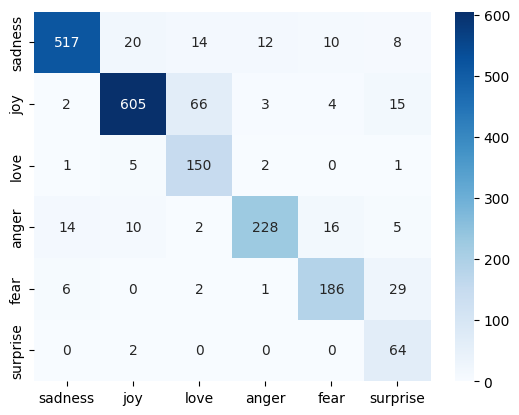

In [45]:
from sklearn.metrics import confusion_matrix

BIGRU_predictions = np.argmax(BIGRU_model.predict(padded_test_sequence),axis=1)
sns.heatmap(confusion_matrix(test_labels, BIGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step


<Axes: >

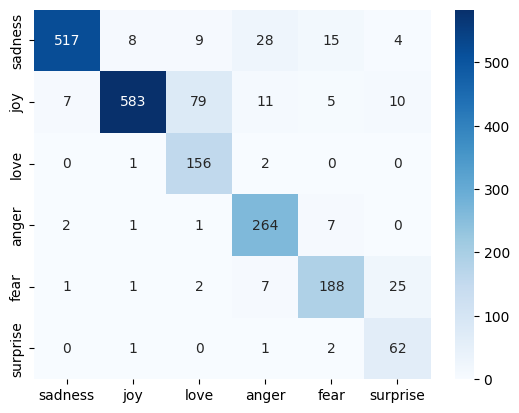

In [46]:
from sklearn.metrics import confusion_matrix

BILSTM_predictions = np.argmax(BILSTM_model.predict(padded_test_sequence),axis=1)
sns.heatmap(confusion_matrix(test_labels, BILSTM_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

# Final Predictions
Test the winning model on unseen sample sentences.

In [52]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts) # Turns each sentence into a list of word IDs using the same tokenizer
sample_padded_sequence = pad_sequences(sample_sequences, maxlen = 50, padding="post", truncating="post") # Makes every sequence exactly 50 long

sample_predictions = np.argmax(BIGRU_model.predict(sample_padded_sequence), axis=1) # Runs the 5 sequences through the trained model
# np.argmax: Picks the index of the highest probability for each sentence.

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}') # Converts the index back to a word.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [53]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequence = pad_sequences(sample_sequences, maxlen = 50, padding="post", truncating="post")

sample_predictions = np.argmax(BILSTM_model.predict(sample_padded_sequence), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


# Importing

In [58]:
import os
import pickle

model_dir = "Artifacts"
os.makedirs(model_dir, exist_ok=True)

#Save our LSTM Model
BILSTM_model.save(os.path.join(model_dir, 'BILSTM_model.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)
